In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [3]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [4]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [5]:
import math
def weighted_avg_and_std(values, weights):
    """
    Return the weighted average and standard deviation.

    values, weights -- Numpy ndarrays with the same shape.
    """
    average = np.average(values, weights=weights)
    # Fast and numerically precise:
    variance = np.average((values-average)**2, weights=weights)
    return (average, math.sqrt(variance))

# Experimental definition
## HERWIG + P8I

In [81]:
observables = ['evid','xsec','pt','n','parton','nch','pt1','q1','eta1','phi1','pid1','parent1','pt2','q2','eta2','phi2','pid2','parent2',\
              'dr','m','nparents1','nparents2']

In [101]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_p8i_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_p8i_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_p8i_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_p8i_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_p8i_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_p8i_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_p8i_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_p8i_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_p8i_50pthat1000_rc_truth.txt']

In [102]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [103]:
df = applyCut(df, 'pt>15')
df.eval('b_ch = q1*q2', inplace=True)
df.eval('e = pt1+pt2', inplace=True)
df.eval('t = 1/(2*pt1/e*pt2*(1-cos(dr)))', inplace=True)

In [104]:
print('number of jets with q1 == -1:', df[df.q1==-1].shape[0])
print('number of jets with q1 == +1:', df[df.q1==1].shape[0])

number of jets with q1 == -1: 819612
number of jets with q1 == +1: 1095563


### Prep for $r_c$ vs $p_T$

In [27]:
df_array = [ df[(df.pt>15) & (df.pt<20)],\
            df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)],\
            df[(df.pt>40) & (df.pt<60)] ]

In [28]:
p8i_rc_array = []
p8i_rc_err_array = []
for i in range(0, len(df_array)):
    p8i_rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    p8i_rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

### Prep for $r_c$ vs $t$

In [105]:
bins = 10.0**(np.arange(0.25,3.25,0.25))
bincenter = (bins[:-1] + bins[1:])/2

In [106]:
#df = applyCut(df, 'pt>30')
df_array = []
for i in range(0, len(bins)-1):
    df_array.append(df[(df.t>bins[i]) & (df.t<bins[i+1])])

In [107]:
p8i_rc_array = []
p8i_rc_err_array = []
for i in range(0, len(df_array)):
    p8i_rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    p8i_rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [125]:
df_pion_array = []
df_k_array = []
df_p_array = []
for i in range(0, len(bins)-1):
    df_pion = applyCut(df, 'abs(pid1)==211 and abs(pid2)==211')
    df_pion_array.append(df_pion[(df_pion.t>bins[i]) & (df_pion.t<bins[i+1])])
    df_k = applyCut(df, 'abs(pid1)==321 and abs(pid2)==321')
    df_k_array.append(df_k[(df_k.t>bins[i]) & (df_k.t<bins[i+1])])
    df_p = applyCut(df, 'abs(pid1)==2212 and abs(pid2)==2212')
    df_p_array.append(df_p[(df_p.t>bins[i]) & (df_p.t<bins[i+1])])

In [126]:
p8i_pion_rc_array = []
p8i_pion_rc_err_array = []
for i in range(0, len(df_pion_array)):
    p8i_pion_rc_array.append(getRcAndErr(df_pion_array[i], 'b_ch')[0])
    p8i_pion_rc_err_array.append(getRcAndErr(df_pion_array[i], 'b_ch')[1])
p8i_k_rc_array = []
p8i_k_rc_err_array = []
for i in range(0, len(df_pion_array)):
    p8i_k_rc_array.append(getRcAndErr(df_k_array[i], 'b_ch')[0])
    p8i_k_rc_err_array.append(getRcAndErr(df_k_array[i], 'b_ch')[1])
p8i_p_rc_array = []
p8i_p_rc_err_array = []
for i in range(0, len(df_pion_array)):
    p8i_p_rc_array.append(getRcAndErr(df_p_array[i], 'b_ch')[0])
    p8i_p_rc_err_array.append(getRcAndErr(df_p_array[i], 'b_ch')[1])

### Prep for 1D distributions

In [42]:
y_p8i, yerr_p8i = calc_hist(df['pt'], bins=np.arange(20,51), weights=df['w'])[:2]

In [10]:
y_p8i, yerr_p8i = calc_hist(df['n'], bins=np.arange(2,16), weights=df['w'], density=True)[:2]

In [13]:
print(weighted_avg_and_std(df['n'], weights=df['w']))

(6.539240967135833, 2.111222616377188)


In [88]:
y_p8i, yerr_p8i = calc_hist(df[df.pt>30]['n'], bins=np.arange(2,16), weights=df[df.pt>30]['w'], density=True)[:2]

In [89]:
print(weighted_avg_and_std(df[df.pt>30]['n'], weights=df[df.pt>30]['w']))

(8.078122363043178, 2.6947917464962634)


## HERWIG default

In [108]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_50pthat1000_rc_truth.txt']

In [109]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [110]:
df = applyCut(df, 'pt>15')
df.eval('b_ch = q1*q2', inplace=True)
df.eval('e = pt1+pt2', inplace=True)
df.eval('t = 1/(2*pt1/e*pt2*(1-cos(dr)))', inplace=True)

In [111]:
print('number of jets with q1 == -1:', df[df.q1==-1].shape[0])
print('number of jets with q1 == +1:', df[df.q1==1].shape[0])

number of jets with q1 == -1: 832254
number of jets with q1 == +1: 1085686


### Prep for $r_c$ vs $p_T$

In [34]:
df_array = [ df[(df.pt>15) & (df.pt<20)],\
            df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)],\
            df[(df.pt>40) & (df.pt<60)]  ]

In [35]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

### Prep for $r_c$ vs $t$

In [112]:
bins = 10.0**(np.arange(0.25,3.25,0.25))
bincenter = (bins[:-1] + bins[1:])/2

In [113]:
#df = applyCut(df, 'pt>30')
df_array = []
for i in range(0, len(bins)-1):
    df_array.append(df[(df.t>bins[i]) & (df.t<bins[i+1])])

In [114]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [133]:
df_pion_array = []
df_k_array = []
df_p_array = []
for i in range(0, len(bins)-1):
    df_pion = applyCut(df, 'abs(pid1)==211 and abs(pid2)==211')
    df_pion_array.append(df_pion[(df_pion.t>bins[i]) & (df_pion.t<bins[i+1])])
    df_k = applyCut(df, 'abs(pid1)==321 and abs(pid2)==321')
    df_k_array.append(df_k[(df_k.t>bins[i]) & (df_k.t<bins[i+1])])
    df_p = applyCut(df, 'abs(pid1)==2212 and abs(pid2)==2212')
    df_p_array.append(df_p[(df_p.t>bins[i]) & (df_p.t<bins[i+1])])

In [134]:
pion_rc_array = []
pion_rc_err_array = []
for i in range(0, len(df_pion_array)):
    pion_rc_array.append(getRcAndErr(df_pion_array[i], 'b_ch')[0])
    pion_rc_err_array.append(getRcAndErr(df_pion_array[i], 'b_ch')[1])
k_rc_array = []
k_rc_err_array = []
for i in range(0, len(df_pion_array)):
    k_rc_array.append(getRcAndErr(df_k_array[i], 'b_ch')[0])
    k_rc_err_array.append(getRcAndErr(df_k_array[i], 'b_ch')[1])
p_rc_array = []
p_rc_err_array = []
for i in range(0, len(df_pion_array)):
    p_rc_array.append(getRcAndErr(df_p_array[i], 'b_ch')[0])
    p_rc_err_array.append(getRcAndErr(df_p_array[i], 'b_ch')[1])

### Prep for 1D distributions

In [18]:
y, yerr = calc_hist(df['n'], bins=np.arange(2,16), weights=df['w'], density=True)[:2]

In [19]:
print(weighted_avg_and_std(df['n'], weights=df['w']))

(6.6555994501682925, 2.1150448569049503)


In [96]:
y, yerr = calc_hist(df[df.pt>30]['n'], bins=np.arange(2,16), weights=df[df.pt>30]['w'], density=True)[:2]

In [97]:
print(weighted_avg_and_std(df[df.pt>30]['n'], weights=df[df.pt>30]['w']))

(8.370940762655579, 2.8069296895181113)


In [47]:
y, yerr = calc_hist(df['pt'], bins=np.arange(20,51), weights=df['w'])[:2]

## Plot

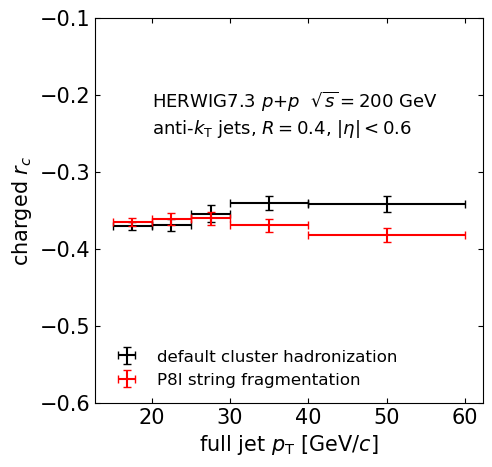

In [39]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_array, capsize=3, ls='none', label='default cluster hadronization', color='k')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], p8i_rc_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=p8i_rc_err_array, capsize=3, ls='none', label='P8I string fragmentation', color='r')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.xlabel(r'full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(20,-0.25,'HERWIG7.3 $p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$', fontsize=15)
plt.ylim(-0.6,-0.1)
plt.legend(fontsize=12, loc='lower left', frameon=False)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

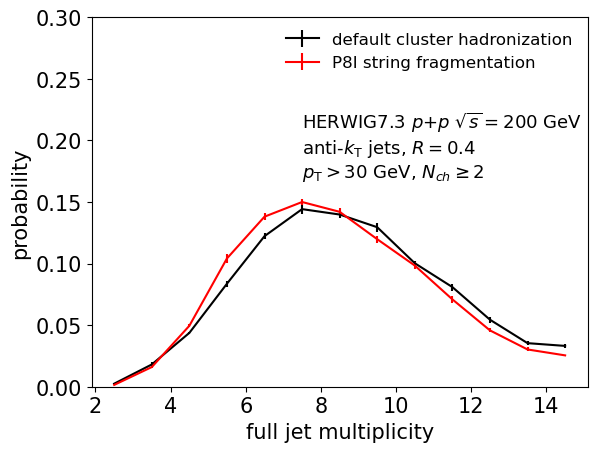

In [48]:
plt.errorbar(np.arange(2.5, 15.5), y, yerr=yerr, color='k', label='default cluster hadronization')
plt.errorbar(np.arange(2.5, 15.5), y_p8i, yerr=yerr_p8i, color='r', label='P8I string fragmentation')
plt.xlabel(r'full jet multiplicity', fontsize=15)
plt.ylabel('probability', fontsize=15)
plt.text(7.5, 0.17,'HERWIG7.3 $p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$\n$p_{\mathrm{T}}>30$ GeV, $N_{ch}\geq2$', fontsize=13)
plt.ylim(0,0.3)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.legend(fontsize=12, loc='upper right', frameon=False)

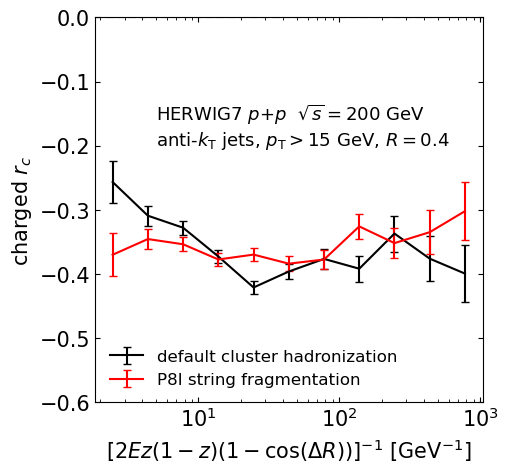

In [117]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(bincenter, rc_array, yerr=rc_err_array, capsize=3, label='default cluster hadronization', color='k')
plt.errorbar(bincenter, p8i_rc_array, yerr=p8i_rc_err_array, capsize=3, label='P8I string fragmentation', color='r')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.xlabel(r'$[2Ez(1-z)(1-\mathrm{cos}(\Delta R))]^{-1}$ [$\mathrm{GeV}^{-1}$]', fontsize=15)
plt.text(5,-0.2,'HERWIG7 $p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $p_{\mathrm{T}} > 15$ GeV, $R=0.4$', fontsize=13)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$', fontsize=15)
plt.ylim(-0.6,0)
plt.legend(fontsize=12, loc='lower left', frameon=False)
plt.xticks(fontsize=15)
plt.xscale('log')
plt.yticks(fontsize=15)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

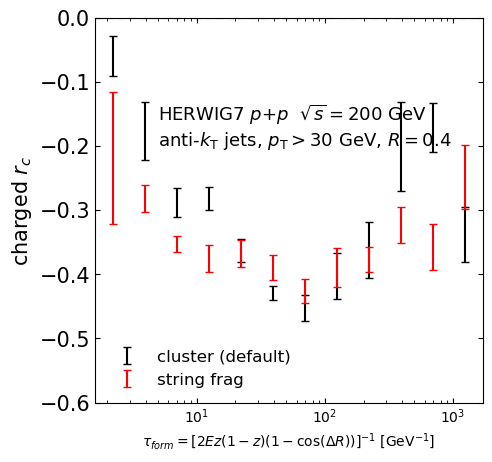

In [80]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(bincenter, rc_array, yerr=rc_err_array, capsize=3, ls='none', label='cluster (default)', color='k')
plt.errorbar(bincenter, p8i_rc_array, yerr=p8i_rc_err_array, capsize=3, ls='none', label='string frag', color='r')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel(r'$\tau_{form} = [2Ez(1-z)(1-\mathrm{cos}(\Delta R))]^{-1}$ [$\mathrm{GeV}^{-1}$]')
plt.text(5,-0.2,'HERWIG7 $p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $p_{\mathrm{T}} > 30$ GeV, $R=0.4$', fontsize=13)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$', fontsize=15)
plt.ylim(-0.6,0)
plt.legend(fontsize=12, loc='lower left', frameon=False)
#plt.xticks(np.arange(20, 45, 5), fontsize=15)
plt.xscale('log')
plt.yticks(fontsize=15)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

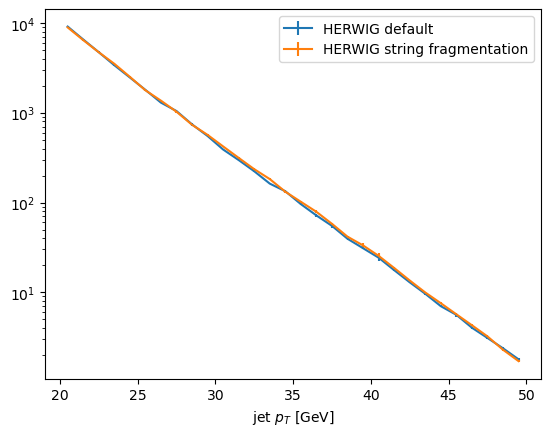

In [49]:
plt.errorbar(np.arange(20.5,50.5), y, yerr=yerr, label='HERWIG default')
plt.errorbar(np.arange(20.5,50.5), y_p8i, yerr=yerr_p8i, label='HERWIG string fragmentation')
plt.xlabel('jet $p_T$ [GeV]')
plt.yscale('log')
plt.legend()

# Original definition
## HERWIG + P8I

In [21]:
observables = ['evid','xsec','pt','n','parton','pt1','q1','eta1','phi1','pid1','parent1','pt2','q2','eta2','phi2','pid2','parent2',\
              'dr','m','nparents1','nparents2']

In [22]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_p8i_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_p8i_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_p8i_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_p8i_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_p8i_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_p8i_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_p8i_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_p8i_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_p8i_50pthat1000_rc_truth.txt']

In [23]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [24]:
df = applyCut(df, 'pt>20')
df.eval('b_ch = q1*q2', inplace=True)

In [25]:
print('number of jets with q1 == -1:', df[df.q1==-1].shape[0])
print('number of jets with q1 == +1:', df[df.q1==1].shape[0])

number of jets with q1 == -1: 241626
number of jets with q1 == +1: 319065


In [26]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [27]:
p8i_rc_array = []
p8i_rc_err_array = []
for i in range(0, len(df_array)):
    p8i_rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    p8i_rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

## HERWIG default

In [28]:
observables = ['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale']

In [29]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_11pthat15_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_15pthat20_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_20pthat25_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_25pthat30_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_30pthat35_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_35pthat40_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_40pthat45_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_45pthat50_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_50pthat_rc.txt']

In [30]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [31]:
df = applyCut(df, 'pt>20 and b!=0 and b!=-9')

In [32]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [33]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b')[1])

## Plot

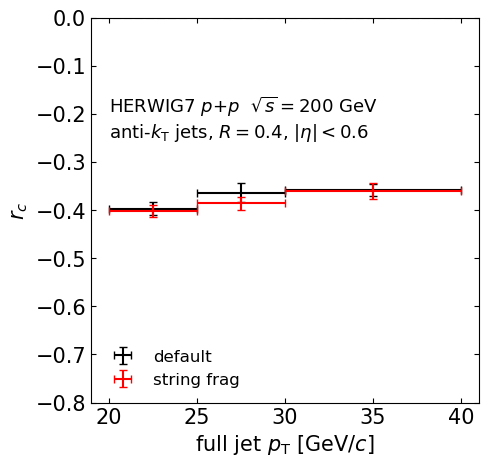

In [34]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_array, xerr=[2.5, 2.5, 5], yerr=rc_err_array, capsize=3, ls='none', label='default', color='k')
plt.errorbar([22.5, 27.5, 35], p8i_rc_array, xerr=[2.5, 2.5, 5], yerr=p8i_rc_err_array, capsize=3, ls='none', label='string frag', color='r')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel(r'full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(20,-0.25,'HERWIG7 $p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$', fontsize=15)
plt.ylim(-0.8,0)
plt.legend(fontsize=12, loc='lower left', frameon=False)
plt.xticks(np.arange(20, 45, 5), fontsize=15)
plt.yticks(fontsize=15)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')